# 01. Preprocessing

Manual check of the preprocessing step: `preprocess_text` on typical and tricky texts, and what `preprocess_dataset` removes.

In [1]:
import pandas as pd

from itg_classification.config import FIGURES_DIR
from itg_classification.eda import (
    class_distribution,
    conflicting_rows,
    imbalance_ratio,
    plot_class_distribution,
)
from itg_classification.load_data import load_dataset
from itg_classification.preprocess import (
    decode_labels,
    preprocess_dataset,
    preprocess_text,
)

pd.set_option("display.max_colwidth", 200)

## 1. One example of every case

The first raw text that contains each pattern, before and after `preprocess_text`.

In [2]:
raw = load_dataset()

cases = {
    "link": r"https?://",
    "retweet and mention": r"^RT @",
    "hashtag": r"#\w",
    "LaTeX quotes": r"``",
    "detached 's": r"\w 's\b",
    "detached n't": r" n't\b",
    "spaced brackets and %": r"\( .* % ",
    "cashtag and prices": r"\$[A-Z]+ .*\$\d",
    "broken encoding": r"\+ñ",
}
examples = pd.DataFrame(
    {
        name: raw.loc[raw["text"].str.contains(p), "text"].iloc[0]
        for name, p in cases.items()
    },
    index=["before"],
).T
examples["after"] = examples["before"].map(preprocess_text)
examples

,before,after
link,$SAP Q1 disappoints as #software licenses down. Real problem? #Cloud growth trails $MSFT $ORCL $GOOG $CRM $ADBE https://t.co/jNDphllzq5,$sap q1 disappoints as software licenses down. real problem? cloud growth trails $msft $orcl $goog $crm $adbe
retweet and mention,"RT @andrewnyquist Chartology: Yahoo: http://stks.co/1itr $YHOO Crazy looking chart, but nearing breakout resistance line...","chartology: yahoo: $yhoo crazy looking chart, but nearing breakout resistance line..."
hashtag,$SAP Q1 disappoints as #software licenses down. Real problem? #Cloud growth trails $MSFT $ORCL $GOOG $CRM $ADBE https://t.co/jNDphllzq5,$sap q1 disappoints as software licenses down. real problem? cloud growth trails $msft $orcl $goog $crm $adbe
LaTeX quotes,`` We are pleased to welcome Tapeks Noma into Cramo group .,we are pleased to welcome tapeks noma into cramo group.
detached 's,"The GeoSolutions technology will leverage Benefon 's GPS solutions by providing Location Based Search Technology , a Communities Platform , location relevant multimedia content and a new and power...","the geosolutions technology will leverage benefon's gps solutions by providing location based search technology, a communities platform, location relevant multimedia content and a new and powerful..."
detached n't,"Marimekko makes all sorts of colorful little impulse buys `` umbrellas , baby bibs , change purses `` and they 're all for sale , the better to take advantage of shoppers who ca n't commit to furn...","marimekko makes all sorts of colorful little impulse buys umbrellas, baby bibs, change purses and they're all for sale, the better to take advantage of shoppers who can't commit to furniture but w..."
spaced brackets and %,"Russia accounted for 9 % of the Lagardere magazine division 's revenue , or EUR 114.40 mn ( USD 148.11 mn ) in 2009 , the USA - for 18 % .","russia accounted for 9% of the lagardere magazine division's revenue, or eur 114.40 mn (usd 148.11 mn) in 2009, the usa - for 18%."
cashtag and prices,"$ESI on lows, down $1.50 to $2.50 BK a real possibility","$esi on lows, down $1.50 to $2.50 bk a real possibility"
broken encoding,"According to L+ñnnen Tehtaat 's CEO Matti Karppinen , the company aims to deliver fish products to its customers a day earlier than it currently does .","according to l+ñnnen tehtaat's ceo matti karppinen, the company aims to deliver fish products to its customers a day earlier than it currently does."


## 2. New texts, as at inference

Texts written by hand, not from the dataset. They must come out in the same style as the training texts.

In [3]:
new_texts = [
    "Nokia's profit FELL by 20% in Q3 :(",
    "RT @trader $AAPL breaking out!!! https://t.co/abc #bullish",
    "  The company   didn't change its outlook .  ",
    "https://example.com",
]
pd.DataFrame({"before": new_texts, "after": map(preprocess_text, new_texts)})

,before,after
0,Nokia's profit FELL by 20% in Q3 :(,nokia's profit fell by 20% in q3 :(
1,RT @trader $AAPL breaking out!!! https://t.co/abc #bullish,$aapl breaking out!!! bullish
2,The company didn't change its outlook .,the company didn't change its outlook.
3,https://example.com,


The last text becomes empty: at inference such an input has to be rejected, there is nothing to classify.

## 3. The whole dataset

In [4]:
processed, removed = preprocess_dataset(raw)
removed

empty                   0
no_letters              0
conflicting_label    1028
duplicate              11
Name: removed, dtype: int64

In [5]:
len(raw), len(processed)

(5842, 4803)

In [6]:
processed.sample(5, random_state=42)

,raw_text,text,label,label_id
596,$TRIP maintains Neutral rating at JP Morgan- PT cut $61 from $66,$trip maintains neutral rating at jp morgan- pt cut $61 from $66,neutral,1
3372,The customer is cooperative retailer Osuuskauppa Suur-Savo .,the customer is cooperative retailer osuuskauppa suur-savo.,neutral,1
2702,NaturalGas Settles At 3-year Low $DBO $BNO http://stks.co/d27qX,naturalgas settles at 3-year low $dbo $bno,negative,0
2473,"Chic and cheerful , Finnish design house Marimekko has been sending its geometric textiles out into the world for the past 60 years .","chic and cheerful, finnish design house marimekko has been sending its geometric textiles out into the world for the past 60 years.",neutral,1
8,"The Stockmann department store will have a total floor space of over 8,000 square metres and Stockmann 's investment in the project will have a price tag of about EUR 12 million .","the stockmann department store will have a total floor space of over 8,000 square metres and stockmann's investment in the project will have a price tag of about eur 12 million.",neutral,1


Every removed conflict, like this pair, is gone from the processed data:

In [7]:
conflicts = conflicting_rows(raw)
conflicts.head(2)

,text,label
3685,"( ADP News ) - Feb 11 , 2009 - Finnish wood products technology supplier Raute Oyj ( HEL : RUTAV ) said today its net profit decreased to EUR 4.7 million ( USD 6.1 m ) for 2008 from EUR 6.6 millio...",negative
4578,"( ADP News ) - Feb 11 , 2009 - Finnish wood products technology supplier Raute Oyj ( HEL : RUTAV ) said today its net profit decreased to EUR 4.7 million ( USD 6.1 m ) for 2008 from EUR 6.6 millio...",neutral


In [8]:
conflicts["text"].map(preprocess_text).isin(processed["text"]).sum()

np.int64(0)

`label_id` decodes back to the same `label` in every row:

In [9]:
decode_labels(processed["label_id"]) == processed["label"].tolist()

True

Preprocessing is stable: running it on processed texts changes nothing.

In [10]:
(processed["text"].map(preprocess_text) == processed["text"]).all()

np.True_

## 4. Classes after preprocessing

In [11]:
distribution = class_distribution(processed)
distribution

,count,share
label,,
negative,343,0.071414
neutral,2610,0.543410
positive,1850,0.385176


In [12]:
imbalance_ratio(distribution)

7.60932944606414

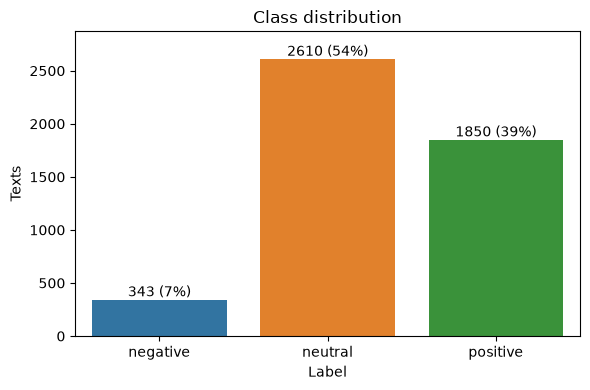

In [13]:
plot_class_distribution(
    processed, FIGURES_DIR / "class_distribution_processed.png"
);

## 5. Summary

- `preprocess_text` removes links, retweet markers and mentions, keeps hashtag words and cashtags, lowercases and undoes the news tokenization. New hand-written texts come out in the same style.
- Broken encodings like `l+ñnnen` stay as they are: the original letters are lost, and they occur only in names.
- `preprocess_dataset` keeps 4,803 of 5,842 rows: 1,028 rows of 514 conflicting texts and 11 duplicates are removed, no text became empty.
- Preprocessing is idempotent and `label_id` matches `label` in every row.
- Without the conflicts `negative` is only 7% of the data, the imbalance grows from 3.6 : 1 to 7.6 : 1. The models will need class weights, and macro F1 stays the main metric.